In [2]:
from google.colab import drive
drive.mount('/content/drive')
DATA = "/content/drive/MyDrive/dates"

Mounted at /content/drive


 Imports & settings

In [3]:

import os, json, time, glob, random, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import keras
from keras import layers, regularizers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, classification_report, confusion_matrix)

SEED      = 42
DRIVE_DIR = "/content/drive/MyDrive/dates"
LOCAL_DIR = "/content/dates"
OUT_DIR   = "/content/drive/MyDrive/dates_project"
VAL_FRAC  = 0.15

for sub in ["results", "figures", "models", "splits"]:
    os.makedirs(os.path.join(OUT_DIR, sub), exist_ok=True)

# Reproducibility
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED); np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPU:", gpus if gpus else "NONE")

TensorFlow: 2.21.0 | Keras: 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Data copy & split

In [4]:

if not os.path.exists(LOCAL_DIR):
    shutil.copytree(DRIVE_DIR, LOCAL_DIR)

CLASSES = sorted(d for d in os.listdir(f"{LOCAL_DIR}/train")
                 if os.path.isdir(f"{LOCAL_DIR}/train/{d}"))
NUM_CLASSES = len(CLASSES)
print(NUM_CLASSES, "classes:", CLASSES)

def list_split(split):
    paths, labels = [], []
    for i, c in enumerate(CLASSES):
        files = sorted(f for f in glob.glob(f"{LOCAL_DIR}/{split}/{c}/*")
                       if f.lower().endswith((".jpg", ".jpeg", ".png")))
        paths += files
        labels += [i] * len(files)
    return np.array(paths), np.array(labels)

trainval_paths, trainval_labels = list_split("train")
test_paths, test_labels = list_split("test")

# Stratified validation split from train
train_paths, val_paths, train_labels, val_labels = train_test_split(
    trainval_paths, trainval_labels, test_size=VAL_FRAC,
    stratify=trainval_labels, random_state=SEED)

print(f"train {len(train_paths)} | val {len(val_paths)} | test {len(test_paths)} "
      f"| total {len(train_paths) + len(val_paths) + len(test_paths)}")

# Save the exact split
for name, p, l in [("train", train_paths, train_labels),
                   ("val", val_paths, val_labels),
                   ("test", test_paths, test_labels)]:
    pd.DataFrame({"path": [os.path.relpath(x, LOCAL_DIR) for x in p],
                  "label": [CLASSES[i] for i in l]}).to_csv(
        f"{OUT_DIR}/splits/{name}.csv", index=False)

9 classes: ['Ajwa', 'Galaxy', 'Mejdool', 'Meneifi', 'NabtatAli', 'Rutab', 'Shaishe', 'Sokari', 'Sugaey']
train 982 | val 174 | test 502 | total 1658


 Class distribution

           train  val  test  total
Ajwa         104   18    53    175
Galaxy       113   20    57    190
Mejdool       80   14    41    135
Meneifi      138   24    70    232
NabtatAli    104   19    54    177
Rutab         87   15    44    146
Shaishe      101   18    52    171
Sokari       156   28    80    264
Sugaey        99   18    51    168
TOTAL        982  174   502   1658


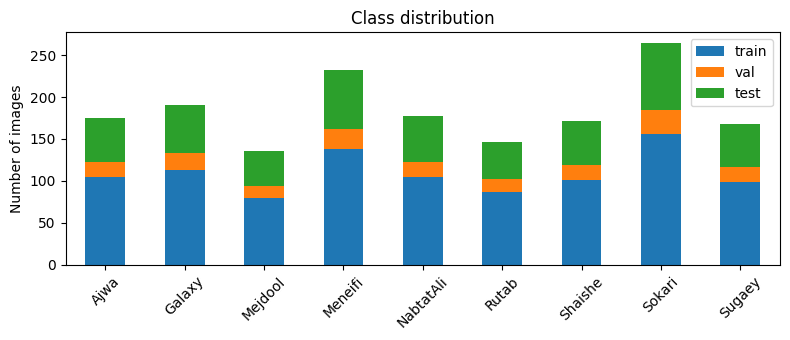

In [5]:

dist = pd.DataFrame({
    "train": np.bincount(train_labels, minlength=NUM_CLASSES),
    "val":   np.bincount(val_labels,   minlength=NUM_CLASSES),
    "test":  np.bincount(test_labels,  minlength=NUM_CLASSES)}, index=CLASSES)
dist["total"] = dist.sum(axis=1)
dist.loc["TOTAL"] = dist.sum()
print(dist)
dist.to_csv(f"{OUT_DIR}/results/class_distribution.csv")

ax = dist.drop("TOTAL")[["train", "val", "test"]].plot(kind="bar", stacked=True, figsize=(8, 3.5))
ax.set_ylabel("Number of images")
ax.set_title("Class distribution")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/figures/class_distribution.png", dpi=300)
plt.show()

Data pipeline & sample images

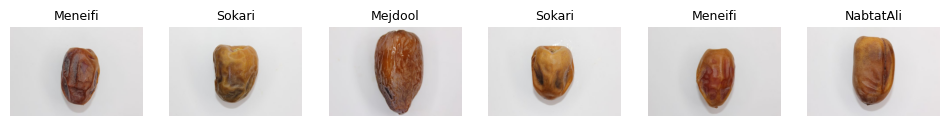

In [6]:

AUTOTUNE = tf.data.AUTOTUNE

def make_ds(paths, labels, img_size, scale01, batch, shuffle):
    def load(p, y):
        img = tf.io.decode_image(tf.io.read_file(p), channels=3, expand_animations=False)
        img = tf.image.resize(img, (img_size, img_size))
        img = tf.cast(img, tf.float32)
        if scale01:
            img = img / 255.0
        return img, y
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load, num_parallel_calls=AUTOTUNE).cache()
    if shuffle:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(batch).prefetch(AUTOTUNE)

# Show 6 random training images
plt.figure(figsize=(12, 3))
idxs = np.random.RandomState(SEED).choice(len(train_paths), 6, replace=False)
for i, idx in enumerate(idxs):
    plt.subplot(1, 6, i + 1)
    plt.imshow(plt.imread(train_paths[idx]))
    plt.title(CLASSES[train_labels[idx]], fontsize=9)
    plt.axis("off")
plt.show()

Evaluation & plotting helpers

In [7]:

def evaluate(model, ds_test, name, train_time_s, extra=None):
    t0 = time.time()
    probs = model.predict(ds_test, verbose=0)
    infer_ms = (time.time() - t0) / len(test_labels) * 1000
    y_pred = probs.argmax(axis=1)

    res = {
        "model": name,
        "test_accuracy":   float(accuracy_score(test_labels, y_pred)),
        "macro_precision": float(precision_score(test_labels, y_pred, average="macro", zero_division=0)),
        "macro_recall":    float(recall_score(test_labels, y_pred, average="macro", zero_division=0)),
        "macro_f1":        float(f1_score(test_labels, y_pred, average="macro", zero_division=0)),
        "params":          int(model.count_params()),
        "train_time_min":  round(train_time_s / 60, 2),
        "inference_ms_per_image": round(infer_ms, 2),
        "gpu": tf.config.experimental.get_device_details(gpus[0]).get("device_name", "GPU") if gpus else "CPU",
    }
    if extra:
        res.update(extra)
    print(json.dumps(res, indent=2))
    print(classification_report(test_labels, y_pred, target_names=CLASSES, digits=3))

    with open(f"{OUT_DIR}/results/{name}_metrics.json", "w") as f:
        json.dump(res, f, indent=2)
    pd.DataFrame(classification_report(test_labels, y_pred, target_names=CLASSES,
                                       output_dict=True, zero_division=0)).T.to_csv(
        f"{OUT_DIR}/results/{name}_per_class.csv")

    cm = confusion_matrix(test_labels, y_pred)
    plt.figure(figsize=(6.5, 5.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES)
    plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(f"{name} - confusion matrix")
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/figures/{name}_confusion_matrix.png", dpi=300)
    plt.show()
    return res

def plot_history(hist, name):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(hist["loss"], label="train"); ax[0].plot(hist["val_loss"], label="val")
    ax[0].set_title(f"{name} - loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(hist["accuracy"], label="train"); ax[1].plot(hist["val_accuracy"], label="val")
    ax[1].set_title(f"{name} - accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/figures/{name}_training_curves.png", dpi=300)
    plt.show()
    with open(f"{OUT_DIR}/results/{name}_history.json", "w") as f:
        json.dump({k: [float(v) for v in vals] for k, vals in hist.items()}, f)

Build B1 (4-layer CNN, Alhamdan & Howe 48-4L)

In [8]:

B1_IMG, B1_BATCH, B1_EPOCHS = 120, 32, 200

b1_train = make_ds(train_paths, train_labels, B1_IMG, True, B1_BATCH, shuffle=True)
b1_val   = make_ds(val_paths,   val_labels,   B1_IMG, True, B1_BATCH, shuffle=False)
b1_test  = make_ds(test_paths,  test_labels,  B1_IMG, True, B1_BATCH, shuffle=False)

def build_b1():
    l2 = regularizers.l2(5e-4)
    return keras.Sequential([
        keras.Input((B1_IMG, B1_IMG, 3)),
        layers.Conv2D(96, 5, activation="relu", kernel_regularizer=l2),
        layers.MaxPooling2D(2),
        layers.Conv2D(128, 5, activation="relu", kernel_regularizer=l2),
        layers.MaxPooling2D(2),
        layers.Conv2D(256, 3, activation="relu", kernel_regularizer=l2),
        layers.Conv2D(256, 3, activation="relu", kernel_regularizer=l2),
        layers.MaxPooling2D(2),
        layers.Flatten(),
        layers.Dense(1024, activation="relu", kernel_regularizer=l2), layers.Dropout(0.5),
        layers.Dense(1024, activation="relu", kernel_regularizer=l2), layers.Dropout(0.5),
        layers.Dense(1024, activation="relu", kernel_regularizer=l2), layers.Dropout(0.5),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ], name="B1_CNN4L")

keras.utils.set_random_seed(SEED)
b1 = build_b1()
b1.compile(optimizer=keras.optimizers.SGD(learning_rate=1e-3),
           loss="sparse_categorical_crossentropy", metrics=["accuracy"])
b1.summary()

Model: "B1_CNN4L"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 116, 116, 96)   │         7,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 58, 58, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 54, 54, 128)    │       307,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 27, 27, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 25, 25, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 23, 23, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 11, 11, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 30976)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │    31,720,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1024)           │     1,049,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1024)           │     1,049,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 9)              │         9,225 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,028,745 (133.62 MB)

 Trainable params: 35,028,745 (133.62 MB)

 Non-trainable params: 0 (0.00 B)

Train & evaluate B1

Epoch 1/200
31/31 - 30s - 961ms/step - accuracy: 0.0967 - loss: 4.4869 - val_accuracy: 0.0805 - val_loss: 4.4861
Epoch 2/200
31/31 - 2s - 63ms/step - accuracy: 0.1191 - loss: 4.4856 - val_accuracy: 0.0805 - val_loss: 4.4843
Epoch 3/200
31/31 - 2s - 63ms/step - accuracy: 0.1069 - loss: 4.4829 - val_accuracy: 0.0920 - val_loss: 4.4824
Epoch 4/200
31/31 - 2s - 64ms/step - accuracy: 0.0967 - loss: 4.4864 - val_accuracy: 0.1379 - val_loss: 4.4807
Epoch 5/200
31/31 - 2s - 64ms/step - accuracy: 0.1120 - loss: 4.4805 - val_accuracy: 0.1379 - val_loss: 4.4793
Epoch 6/200
31/31 - 2s - 65ms/step - accuracy: 0.1324 - loss: 4.4779 - val_accuracy: 0.1379 - val_loss: 4.4780
Epoch 7/200
31/31 - 2s - 64ms/step - accuracy: 0.1283 - loss: 4.4815 - val_accuracy: 0.1494 - val_loss: 4.4771
Epoch 8/200
31/31 - 2s - 64ms/step - accuracy: 0.1283 - loss: 4.4786 - val_accuracy: 0.1667 - val_loss: 4.4758
Epoch 9/200
31/31 - 2s - 64ms/step - accuracy: 0.1385 - loss: 4.4773 - val_accuracy: 0.1609 - val_loss: 4.4747

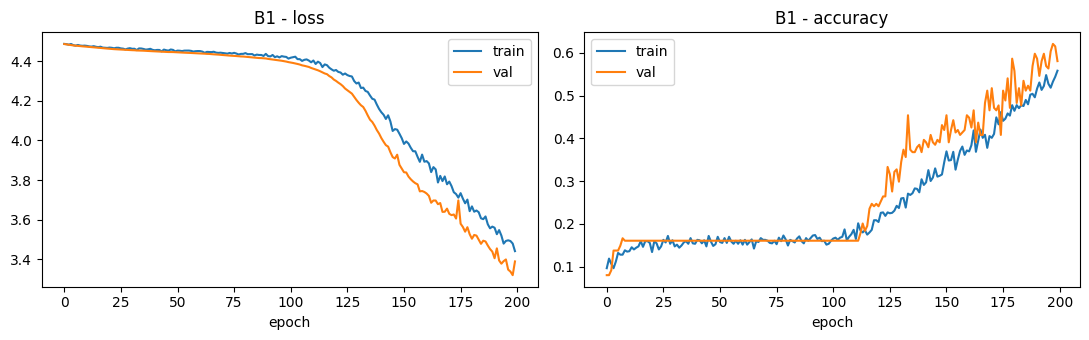

{
  "model": "B1",
  "test_accuracy": 0.6713147410358565,
  "macro_precision": 0.69623374174409,
  "macro_recall": 0.6516307870653354,
  "macro_f1": 0.6358124973517411,
  "params": 35028745,
  "train_time_min": 7.79,
  "inference_ms_per_image": 3.88,
  "gpu": "Tesla T4",
  "epochs_run": 200,
  "img_size": 120
}
              precision    recall  f1-score   support

        Ajwa      0.883     1.000     0.938        53
      Galaxy      0.721     0.544     0.620        57
     Mejdool      0.630     0.707     0.667        41
     Meneifi      0.597     0.657     0.626        70
   NabtatAli      0.583     0.259     0.359        54
       Rutab      0.818     0.205     0.327        44
     Shaishe      0.857     0.692     0.766        52
      Sokari      0.664     0.938     0.777        80
      Sugaey      0.512     0.863     0.642        51

    accuracy                          0.671       502
   macro avg      0.696     0.652     0.636       502
weighted avg      0.691     0.671    

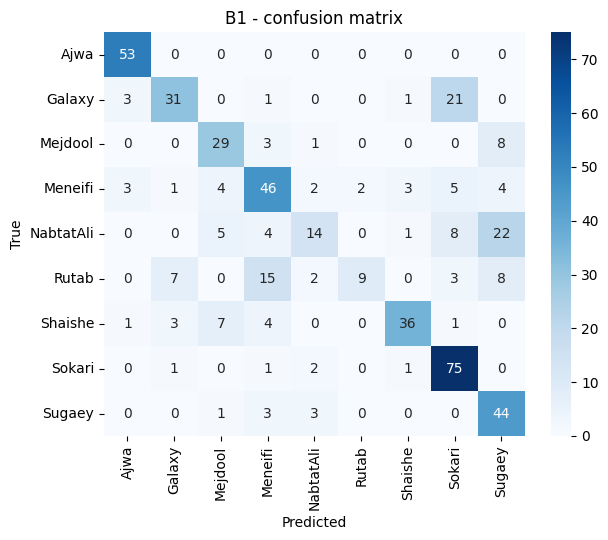

In [9]:

t0 = time.time()
h1 = b1.fit(b1_train, validation_data=b1_val, epochs=B1_EPOCHS, verbose=2,
            callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=30,
                                                     restore_best_weights=True)])
b1_time = time.time() - t0

plot_history(h1.history, "B1")
res_b1 = evaluate(b1, b1_test, "B1", b1_time,
                  extra={"epochs_run": len(h1.history["loss"]), "img_size": B1_IMG})
b1.save(f"{OUT_DIR}/models/B1.keras")

Re-train B1 with SGD momentum 0.9

Epoch 1/200
31/31 - 15s - 483ms/step - accuracy: 0.0998 - loss: 4.4887 - val_accuracy: 0.1609 - val_loss: 4.4786
Epoch 2/200
31/31 - 2s - 70ms/step - accuracy: 0.1538 - loss: 4.4762 - val_accuracy: 0.1609 - val_loss: 4.4708
Epoch 3/200
31/31 - 2s - 69ms/step - accuracy: 0.1558 - loss: 4.4692 - val_accuracy: 0.1609 - val_loss: 4.4642
Epoch 4/200
31/31 - 2s - 69ms/step - accuracy: 0.1568 - loss: 4.4643 - val_accuracy: 0.1609 - val_loss: 4.4580
Epoch 5/200
31/31 - 2s - 70ms/step - accuracy: 0.1466 - loss: 4.4599 - val_accuracy: 0.1609 - val_loss: 4.4528
Epoch 6/200
31/31 - 2s - 71ms/step - accuracy: 0.1477 - loss: 4.4533 - val_accuracy: 0.1609 - val_loss: 4.4495
Epoch 7/200
31/31 - 2s - 71ms/step - accuracy: 0.1589 - loss: 4.4578 - val_accuracy: 0.1609 - val_loss: 4.4494
Epoch 8/200
31/31 - 2s - 72ms/step - accuracy: 0.1538 - loss: 4.4575 - val_accuracy: 0.1609 - val_loss: 4.4466
Epoch 9/200
31/31 - 3s - 83ms/step - accuracy: 0.1619 - loss: 4.4509 - val_accuracy: 0.1609 - val_loss: 4.4460

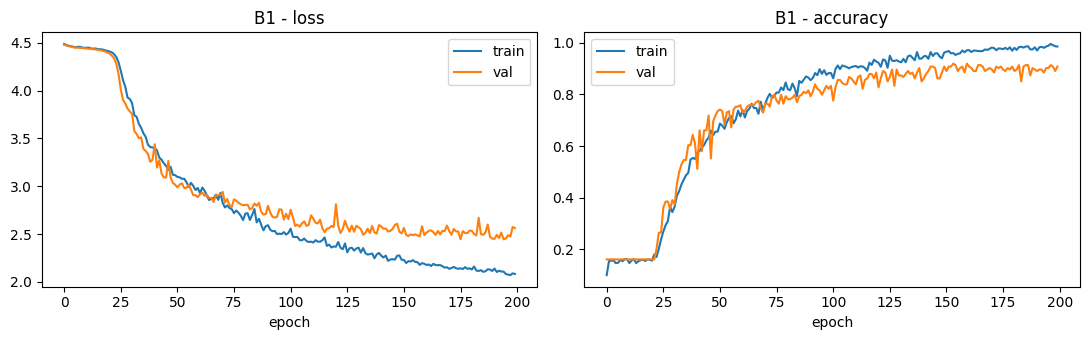

{
  "model": "B1",
  "test_accuracy": 0.8884462151394422,
  "macro_precision": 0.8866102924351704,
  "macro_recall": 0.8908556555186432,
  "macro_f1": 0.8881275459176602,
  "params": 35028745,
  "train_time_min": 7.49,
  "inference_ms_per_image": 2.65,
  "gpu": "Tesla T4",
  "epochs_run": 200,
  "img_size": 120,
  "sgd_momentum": 0.9
}
              precision    recall  f1-score   support

        Ajwa      0.930     1.000     0.964        53
      Galaxy      0.943     0.877     0.909        57
     Mejdool      0.818     0.878     0.847        41
     Meneifi      0.829     0.829     0.829        70
   NabtatAli      0.836     0.852     0.844        54
       Rutab      0.870     0.909     0.889        44
     Shaishe      0.980     0.942     0.961        52
      Sokari      0.947     0.887     0.916        80
      Sugaey      0.827     0.843     0.835        51

    accuracy                          0.888       502
   macro avg      0.887     0.891     0.888       502
weighted avg

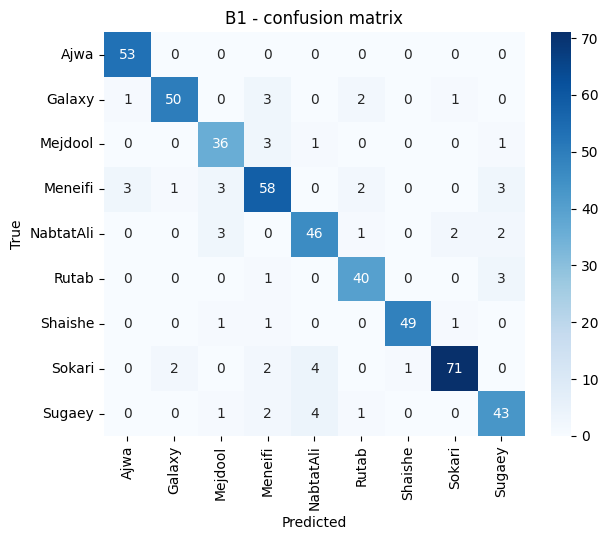

In [10]:

# Keep the plain-SGD run under a different name
for f in glob.glob(f"{OUT_DIR}/results/B1_*") + glob.glob(f"{OUT_DIR}/figures/B1_*"):
    shutil.copy(f, f.replace("B1_", "B1_plainSGD_"))
res_b1_plain = res_b1

keras.utils.set_random_seed(SEED)
b1 = build_b1()
b1.compile(optimizer=keras.optimizers.SGD(learning_rate=1e-3, momentum=0.9),
           loss="sparse_categorical_crossentropy", metrics=["accuracy"])

t0 = time.time()
h1 = b1.fit(b1_train, validation_data=b1_val, epochs=B1_EPOCHS, verbose=2,
            callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=30,
                                                     restore_best_weights=True)])
b1_time = time.time() - t0

plot_history(h1.history, "B1")
res_b1 = evaluate(b1, b1_test, "B1", b1_time,
                  extra={"epochs_run": len(h1.history["loss"]), "img_size": B1_IMG,
                         "sgd_momentum": 0.9})
b1.save(f"{OUT_DIR}/models/B1.keras")

Build B2 (MobileNetV3-Large, ImageNet)

In [11]:

B2_IMG, B2_BATCH = 224, 32

b2_train = make_ds(train_paths, train_labels, B2_IMG, False, B2_BATCH, shuffle=True)
b2_val   = make_ds(val_paths,   val_labels,   B2_IMG, False, B2_BATCH, shuffle=False)
b2_test  = make_ds(test_paths,  test_labels,  B2_IMG, False, B2_BATCH, shuffle=False)

def build_b2():
    base = keras.applications.MobileNetV3Large(
        input_shape=(B2_IMG, B2_IMG, 3), include_top=False,
        weights="imagenet", include_preprocessing=True)
    inp = keras.Input((B2_IMG, B2_IMG, 3))
    x = base(inp, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.2)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inp, out, name="B2_MobileNetV3"), base

keras.utils.set_random_seed(SEED)
b2, b2_base = build_b2()
print("Backbone output shape:", b2_base.output.shape)
b2.summary()

12683000/12683000 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Backbone output shape: (None, 7, 7, 960)


Model: "B2_MobileNetV3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MobileNetV3Large (Functional)   │ (None, 7, 7, 960)      │     2,996,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 960)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 960)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 9)              │         8,649 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,005,001 (11.46 MB)

 Trainable params: 2,980,601 (11.37 MB)

 Non-trainable params: 24,400 (95.31 KB)

Train & evaluate B2

Epoch 1/5
31/31 - 41s - 1s/step - accuracy: 0.3157 - loss: 2.0702 - val_accuracy: 0.6322 - val_loss: 1.1925
Epoch 2/5
31/31 - 1s - 35ms/step - accuracy: 0.6965 - loss: 0.9857 - val_accuracy: 0.8621 - val_loss: 0.7372
Epoch 3/5
31/31 - 1s - 34ms/step - accuracy: 0.8493 - loss: 0.6111 - val_accuracy: 0.9023 - val_loss: 0.5264
Epoch 4/5
31/31 - 1s - 33ms/step - accuracy: 0.8717 - loss: 0.4665 - val_accuracy: 0.9253 - val_loss: 0.4353
Epoch 5/5
31/31 - 1s - 34ms/step - accuracy: 0.9002 - loss: 0.3959 - val_accuracy: 0.9310 - val_loss: 0.3815
Epoch 1/30
31/31 - 126s - 4s/step - accuracy: 0.7678 - loss: 0.7686 - val_accuracy: 0.7931 - val_loss: 0.5886
Epoch 2/30
31/31 - 3s - 98ms/step - accuracy: 0.9684 - loss: 0.1356 - val_accuracy: 0.8103 - val_loss: 0.5501
Epoch 3/30
31/31 - 3s - 97ms/step - accuracy: 0.9868 - loss: 0.0517 - val_accuracy: 0.8276 - val_loss: 0.5072
Epoch 4/30
31/31 - 3s - 99ms/step - accuracy: 0.9969 - loss: 0.0277 - val_accuracy: 0.8506 - val_loss: 0.4644
Epoch 5/30
31/31

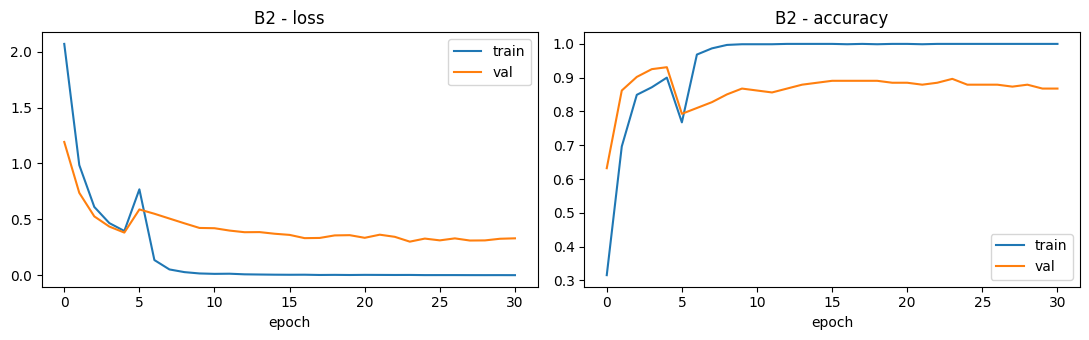

{
  "model": "B2",
  "test_accuracy": 0.8884462151394422,
  "macro_precision": 0.9018264732869442,
  "macro_recall": 0.8879094633675849,
  "macro_f1": 0.8862313064028566,
  "params": 3005001,
  "train_time_min": 4.08,
  "inference_ms_per_image": 20.37,
  "gpu": "Tesla T4",
  "epochs_run": 31,
  "img_size": 224
}
              precision    recall  f1-score   support

        Ajwa      1.000     0.981     0.990        53
      Galaxy      0.978     0.789     0.874        57
     Mejdool      0.833     0.976     0.899        41
     Meneifi      0.833     0.857     0.845        70
   NabtatAli      0.981     0.944     0.962        54
       Rutab      0.710     1.000     0.830        44
     Shaishe      0.975     0.750     0.848        52
      Sokari      0.859     0.988     0.919        80
      Sugaey      0.947     0.706     0.809        51

    accuracy                          0.888       502
   macro avg      0.902     0.888     0.886       502
weighted avg      0.903     0.888   

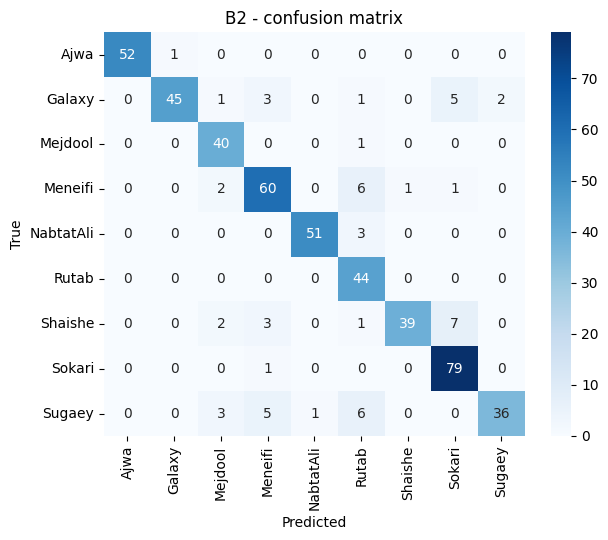

In [12]:

t0 = time.time()

# Stage 1: train the head only
b2_base.trainable = False
b2.compile(optimizer=keras.optimizers.Adam(1e-3),
           loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h2a = b2.fit(b2_train, validation_data=b2_val, epochs=5, verbose=2)

# Stage 2: fine-tune the whole network
b2_base.trainable = True
b2.compile(optimizer=keras.optimizers.Adam(1e-4),
           loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h2b = b2.fit(b2_train, validation_data=b2_val, epochs=30, verbose=2,
             callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=7,
                                                      restore_best_weights=True)])
b2_time = time.time() - t0

h2 = {k: h2a.history[k] + h2b.history[k] for k in h2a.history}
plot_history(h2, "B2")
res_b2 = evaluate(b2, b2_test, "B2", b2_time,
                  extra={"epochs_run": len(h2["loss"]), "img_size": B2_IMG})
b2.save(f"{OUT_DIR}/models/B2.keras")

Re-train B2 with a lower fine-tuning learning rate

Epoch 1/5
31/31 - 26s - 831ms/step - accuracy: 0.3259 - loss: 2.1386 - val_accuracy: 0.6379 - val_loss: 1.2115
Epoch 2/5
31/31 - 1s - 35ms/step - accuracy: 0.6935 - loss: 1.0043 - val_accuracy: 0.8563 - val_loss: 0.7192
Epoch 3/5
31/31 - 1s - 39ms/step - accuracy: 0.8360 - loss: 0.6375 - val_accuracy: 0.8908 - val_loss: 0.5400
Epoch 4/5
31/31 - 1s - 32ms/step - accuracy: 0.8859 - loss: 0.4714 - val_accuracy: 0.9080 - val_loss: 0.4406
Epoch 5/5
31/31 - 1s - 33ms/step - accuracy: 0.9043 - loss: 0.3868 - val_accuracy: 0.9195 - val_loss: 0.3739
Epoch 1/30
31/31 - 79s - 3s/step - accuracy: 0.3788 - loss: 1.7645 - val_accuracy: 0.9253 - val_loss: 0.3789
Epoch 2/30
31/31 - 3s - 96ms/step - accuracy: 0.5611 - loss: 1.2364 - val_accuracy: 0.9138 - val_loss: 0.3859
Epoch 3/30
31/31 - 3s - 95ms/step - accuracy: 0.7403 - loss: 0.9132 - val_accuracy: 0.9080 - val_loss: 0.3913
Epoch 4/30
31/31 - 3s - 96ms/step - accuracy: 0.8228 - loss: 0.6851 - val_accuracy: 0.8908 - val_loss: 0.3957
Epoch 5/30
31/

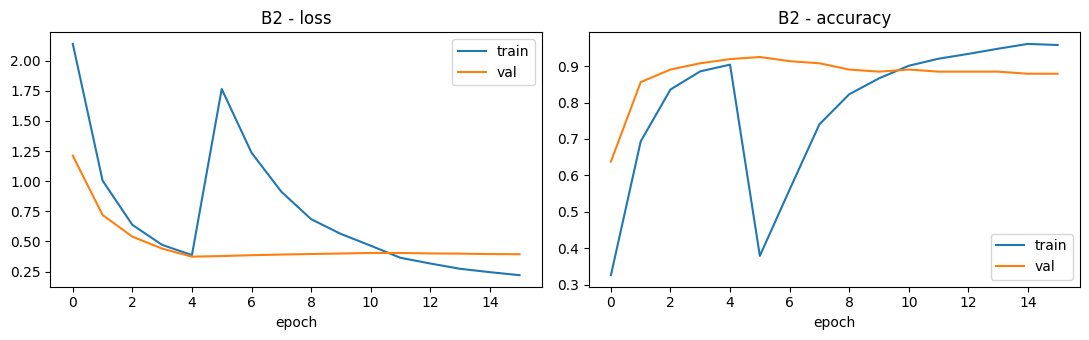

{
  "model": "B2",
  "test_accuracy": 0.9322709163346613,
  "macro_precision": 0.9423643194651599,
  "macro_recall": 0.9291425759521064,
  "macro_f1": 0.9334265962946154,
  "params": 3005001,
  "train_time_min": 2.32,
  "inference_ms_per_image": 18.68,
  "gpu": "Tesla T4",
  "epochs_run": 16,
  "img_size": 224,
  "finetune_lr": 1e-05
}
              precision    recall  f1-score   support

        Ajwa      1.000     1.000     1.000        53
      Galaxy      0.980     0.842     0.906        57
     Mejdool      1.000     0.878     0.935        41
     Meneifi      0.844     0.929     0.884        70
   NabtatAli      1.000     0.963     0.981        54
       Rutab      0.843     0.977     0.905        44
     Shaishe      1.000     0.923     0.960        52
      Sokari      0.898     0.988     0.940        80
      Sugaey      0.917     0.863     0.889        51

    accuracy                          0.932       502
   macro avg      0.942     0.929     0.933       502
weighted avg

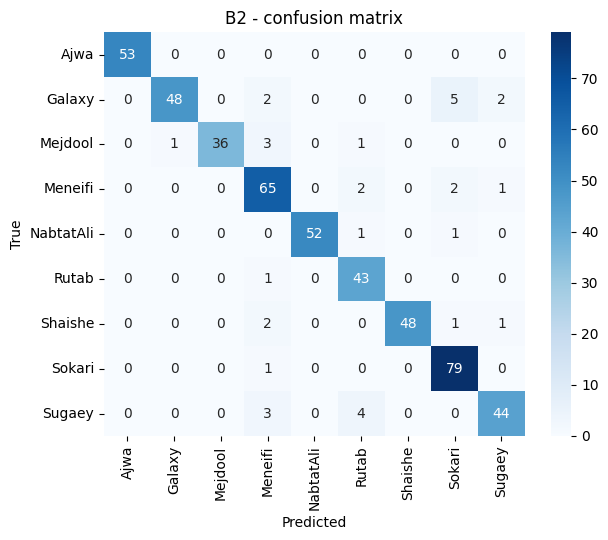

In [13]:

for f in glob.glob(f"{OUT_DIR}/results/B2_*") + glob.glob(f"{OUT_DIR}/figures/B2_*"):
    shutil.copy(f, f.replace("B2_", "B2_lr1e-4_"))
res_b2_lr4 = res_b2

keras.utils.set_random_seed(SEED)
b2, b2_base = build_b2()
t0 = time.time()

# Stage 1: train the head only
b2_base.trainable = False
b2.compile(optimizer=keras.optimizers.Adam(1e-3),
           loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h2a = b2.fit(b2_train, validation_data=b2_val, epochs=5, verbose=2)

# Stage 2: fine-tune the whole network with a small learning rate
b2_base.trainable = True
b2.compile(optimizer=keras.optimizers.Adam(1e-5),
           loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h2b = b2.fit(b2_train, validation_data=b2_val, epochs=30, verbose=2,
             callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=10,
                                                      restore_best_weights=True)])
b2_time = time.time() - t0

h2 = {k: h2a.history[k] + h2b.history[k] for k in h2a.history}
plot_history(h2, "B2")
res_b2 = evaluate(b2, b2_test, "B2", b2_time,
                  extra={"epochs_run": len(h2["loss"]), "img_size": B2_IMG,
                         "finetune_lr": 1e-5})
b2.save(f"{OUT_DIR}/models/B2.keras")

Fair inference timing & summary table

In [14]:

def time_inference(model, ds, n_runs=5):
    model.predict(ds, verbose=0)  # warm-up
    times = []
    for _ in range(n_runs):
        t0 = time.time()
        model.predict(ds, verbose=0)
        times.append(time.time() - t0)
    return np.mean(times) / len(test_labels) * 1000

b1_ms = time_inference(b1, b1_test)
b2_ms = time_inference(b2, b2_test)
print(f"B1: {b1_ms:.2f} ms/image | B2: {b2_ms:.2f} ms/image")

for res, ms in [(res_b1, b1_ms), (res_b2, b2_ms)]:
    res["inference_ms_per_image"] = round(ms, 2)
    with open(f"{OUT_DIR}/results/{res['model']}_metrics.json", "w") as f:
        json.dump(res, f, indent=2)

rows = [
    ("B1: 4-layer CNN, plain SGD", res_b1_plain, "ours"),
    ("B1: 4-layer CNN, SGD momentum 0.9", res_b1, "ours"),
    ("B2: MobileNetV3, fine-tune lr 1e-4", res_b2_lr4, "ours"),
    ("B2: MobileNetV3, fine-tune lr 1e-5", res_b2, "ours"),
]
summary = pd.DataFrame([{
    "Model": n, "Accuracy": r["test_accuracy"], "Macro-F1": r["macro_f1"],
    "Params (M)": r["params"] / 1e6, "Train time (min)": r["train_time_min"], "Source": s}
    for n, r, s in rows])

published = pd.DataFrame([
    {"Model": "Alhamdan & Howe [1], 48-4L", "Accuracy": 0.96, "Source": "quoted"},
    {"Model": "Alhamdan & Howe [1], 70-4L (best)", "Accuracy": 0.97, "Source": "quoted"},
    {"Model": "Adnan & Nasharuddin [2]", "Accuracy": 0.942, "Source": "quoted"},
])
summary = pd.concat([summary, published], ignore_index=True)
summary.to_csv(f"{OUT_DIR}/results/summary.csv", index=False)
summary.round(4)

B1: 0.60 ms/image | B2: 0.87 ms/image


,Model,Accuracy,Macro-F1,Params (M),Train time (min),Source
0,"B1: 4-layer CNN, plain SGD",0.6713,0.6358,35.0287,7.79,ours
1,"B1: 4-layer CNN, SGD momentum 0.9",0.8884,0.8881,35.0287,7.49,ours
2,"B2: MobileNetV3, fine-tune lr 1e-4",0.8884,0.8862,3.0050,4.08,ours
3,"B2: MobileNetV3, fine-tune lr 1e-5",0.9323,0.9334,3.0050,2.32,ours
4,"Alhamdan & Howe [1], 48-4L",0.9600,NaN,NaN,NaN,quoted
5,"Alhamdan & Howe [1], 70-4L (best)",0.9700,NaN,NaN,NaN,quoted
6,Adnan & Nasharuddin [2],0.9420,NaN,NaN,NaN,quoted
